# Lab 8 Optimizing Image Mosaic Generator

Student: Qizhuo Shen

Date: 11/24/2026

## Part 1: Profiling My Lab 1 Mosaic Generator

For this part, I want to find out where my Lab 1 code spends its time, before I change anything. To do that, I use three tools. Simple timing shows the total time, `cProfile` can help identify which functions are slow, and `line_profiler` can help find which lines are slow.

### Which Baseline I Use

My Lab 1 code is kept unchanged in the `baseline/` folder. Its `baseline/core.py` has two versions of the grid operations, as shown in the table below:

| Version | Function | How it works |
|---|---|---|
| **Loop version** | `build_mosaic_loop` → `grid_ops_loop` | Goes through the grid one cell at a time with Python loops. For each cell it loops over all tiles to find the closest one, then colors the tile and pastes it into the output. |
| Vectorized version | `build_mosaic` → `grid_ops` | Uses NumPy reshape to get all cell colors at once, compares all cells to all tiles in one step, and builds the output with one indexing operation. |

My Lab 1 code was already vectorized, so **I use the loop version (`build_mosaic_loop`) as my baseline**. It is a normal loop version. I did not add any sleeps or extra work to make it slower. I also time the vectorized Lab 1 version next to it, so that in Part 2 I can compare my new code against both.

### 1. Setup

I installed `line_profiler` in the Lab's virtual environment with `pip install line_profiler`. Loading it as an extension gives me the `%lprun` command in Jupyter. `cProfile` and `pstats` come with Python, so they need no install.

In [15]:
%load_ext line_profiler

import cProfile
import io
import platform
import pstats
import time
from pathlib import Path

import cv2
import line_profiler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from baseline import core, tiles
from baseline.core import build_mosaic, build_mosaic_loop

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print(f"Python         {platform.python_version()} ({platform.system()} {platform.machine()})")
print(f"CPU            {platform.processor()}")
print(f"NumPy          {np.__version__}")
print(f"OpenCV         {cv2.__version__}")
print(f"line_profiler  {line_profiler.__version__}")

The line_profiler extension is already loaded. To reload it, use:
  %reload_ext line_profiler
Python         3.14.3 (Windows AMD64)
CPU            Intel64 Family 6 Model 198 Stepping 2, GenuineIntel
NumPy          2.5.3
OpenCV         5.0.0
line_profiler  5.1.0


#### Test Images and Settings

**Images:** I use three sunflower photos, one for each size the lab asks for (256×256, 512×512 and 1024×1024). They are shown below.

**Configurations:** I use the three configurations the lab requires, which are 256×256 with a 16×16 grid, 512×512 with a 32×32 grid, and 1024×1024 with a 64×64 grid. All three have 16 px cells.

**Other settings:** I use the app's defaults, which are the *Halftone Dots* tile set, *Modulate* color mode, strength 0.85, RGB matching and no color quantization. But I change two settings to make sure the test measures correctly.

* `long_edge = image size`. By default the app resizes every image to 768 px first. But this will cause that all three image sizes cost the same, and the test would be pointless. So I set it to the image's own size without resizing.
* `tile_px = image size // grid`. I draw each tile at the same size as its cell, so the mosaic has the same size as the input. For example, a 512×512 image with a 32×32 grid has 16 px cells and gives a 512×512 mosaic.

In [16]:
IMAGE_FILES = {
    256: Path("assets/vibrant-sunflower-bloom-stockcake-256x256.jpg"),
    512: Path("assets/vibrant-sunflower-bloom-stockcake-512x512.jpg"),
    1024: Path("assets/sunflower-1024x1024.jpg"),
}
CONFIGS = [(256, 16), (512, 32), (1024, 64)]   # (image size, grid size), as the lab requires
CONFIG_LABELS = [f"{size}×{size} / {grid}×{grid}" for size, grid in CONFIGS]

TILE_SET = "Halftone Dots"
COLOR_MODE = "Modulate"
STRENGTH = 0.85


def load_rgb(path: Path) -> np.ndarray:
    """Read an image file as an RGB uint8 array (OpenCV loads BGR)."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def settings(size: int, grid: int) -> dict:
    """Keyword arguments for build_mosaic / build_mosaic_loop for one configuration."""
    return dict(grid_size=grid, tile_set_name=TILE_SET, tile_px=size // grid,
                color_mode=COLOR_MODE, strength=STRENGTH, long_edge=size)


test_images = {size: load_rgb(path) for size, path in IMAGE_FILES.items()}

for size, img in test_images.items():
    assert img.shape == (size, size, 3), f"{IMAGE_FILES[size]} is {img.shape}, expected {size}x{size}"
    print(f"{size:>4}px  {IMAGE_FILES[size].name:<48} shape={img.shape} dtype={img.dtype}")

print("\nConfigurations:")
for (size, grid), label in zip(CONFIGS, CONFIG_LABELS):
    print(f"  {label:<18} -> {grid * grid:>5} cells of {size // grid}px")

 256px  vibrant-sunflower-bloom-stockcake-256x256.jpg    shape=(256, 256, 3) dtype=uint8
 512px  vibrant-sunflower-bloom-stockcake-512x512.jpg    shape=(512, 512, 3) dtype=uint8
1024px  sunflower-1024x1024.jpg                          shape=(1024, 1024, 3) dtype=uint8

Configurations:
  256×256 / 16×16    ->   256 cells of 16px
  512×512 / 32×32    ->  1024 cells of 16px
  1024×1024 / 64×64  ->  4096 cells of 16px


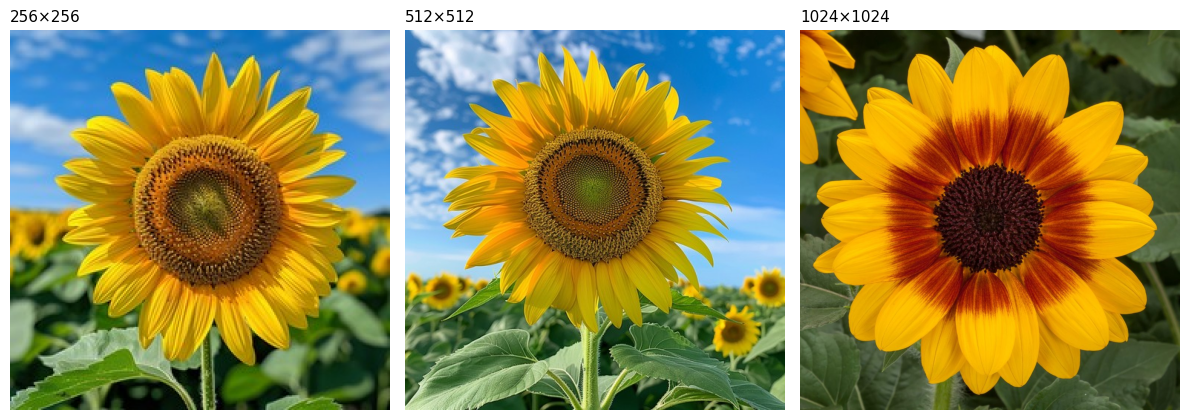

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (size, img) in zip(axes, test_images.items()):
    ax.imshow(img)
    ax.set_title(f"{size}×{size}", loc="left", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2. Baseline Performance

#### Timing the Whole Mosaic Generation

I time one full call to `build_mosaic_loop` for each configuration. This includes every step of making a mosaic, which includes preprocessing, cropping, computing the cell colors, matching tiles, building the output and the grid preview.

Before timing, I run each configuration once as a warm-up. The first call builds the tile set and saves it in a cache, and NumPy also needs to set up memory the first time. This only happens once, so it should not count in the normal running time. After the warm-up I run each configuration 5 times and report the mean and standard deviation.

I also time the vectorized Lab 1 version (`build_mosaic`) in the same way, so I can see how far apart the two versions are.

In [18]:
REPEATS = 5


def time_call(fn, *args, repeats=REPEATS, **kwargs):
    """Mean and standard deviation (ms) of `repeats` calls, after one warm-up call."""
    fn(*args, **kwargs)  # warm-up: fills the tile-set cache, first-touch allocations
    samples = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn(*args, **kwargs)
        samples.append((time.perf_counter() - t0) * 1000)
    return float(np.mean(samples)), float(np.std(samples))


rows = []
for size, grid in CONFIGS:
    img, kw = test_images[size], settings(size, grid)
    loop_ms, loop_sd = time_call(build_mosaic_loop, img, **kw)
    vec_ms, vec_sd = time_call(build_mosaic, img, **kw)
    rows.append(dict(size=size, grid=grid, cells=grid * grid,
                     loop_ms=loop_ms, loop_sd=loop_sd, vec_ms=vec_ms, vec_sd=vec_sd))

timings = pd.DataFrame(rows)
timings["loop_vs_vec"] = timings.loop_ms / timings.vec_ms
timings.to_csv(RESULTS / "baseline_timings.csv", index=False)

pd.DataFrame({
    "Configuration": CONFIG_LABELS,
    "Cells": timings.cells,
    "Baseline loop (ms)": [f"{m:.2f} ± {s:.2f}" for m, s in zip(timings.loop_ms, timings.loop_sd)],
    "Lab 1 vectorized (ms)": [f"{m:.2f} ± {s:.2f}" for m, s in zip(timings.vec_ms, timings.vec_sd)],
    "Loop ÷ vectorized": timings.loop_vs_vec.map("{:.2f}×".format),
})

,Configuration,Cells,Baseline loop (ms),Lab 1 vectorized (ms),Loop ÷ vectorized
0,256×256 / 16×16,256,4.95 ± 0.24,2.16 ± 0.18,2.29×
1,512×512 / 32×32,1024,19.69 ± 0.74,12.00 ± 0.17,1.64×
2,1024×1024 / 64×64,4096,79.55 ± 1.70,48.34 ± 0.66,1.65×


#### How the Time Grows with the Configuration

I draw both versions on one chart, from the smallest to the largest configuration. The y-axis uses a log scale, because the times grow by about 4 times at each step. The error bars show the standard deviation over the 5 runs.

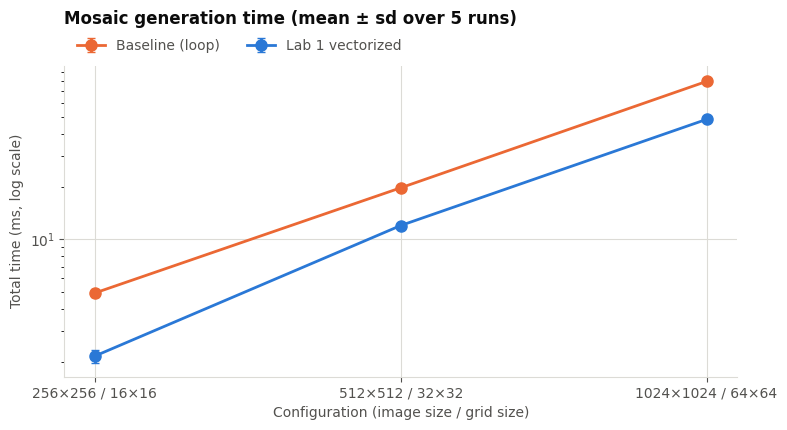

In [19]:
C_LOOP, C_VEC = "#eb6834", "#2a78d6"   # same color pair as mosaic/benchmark.py
INK, MUTED, GRID_INK = "#0b0b0b", "#52514e", "#dcdbd6"


def style_axes(ax, grid_axis="both"):
    """Recessive grid and spines, shared by all charts in this notebook."""
    ax.grid(True, axis=grid_axis, color=GRID_INK, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID_INK)
    ax.tick_params(colors=MUTED)


x = np.arange(len(CONFIGS))
fig, ax = plt.subplots(figsize=(8, 4.4))
for col, sd, color, label in (("loop_ms", "loop_sd", C_LOOP, "Baseline (loop)"),
                              ("vec_ms", "vec_sd", C_VEC, "Lab 1 vectorized")):
    ax.errorbar(x, timings[col], yerr=timings[sd], color=color, lw=2, marker="o", ms=8,
                capsize=3, label=label)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(CONFIG_LABELS, color=INK)
ax.set_xlabel("Configuration (image size / grid size)", color=MUTED)
ax.set_ylabel("Total time (ms, log scale)", color=MUTED)
style_axes(ax)
ax.set_title("Mosaic generation time (mean ± sd over 5 runs)", loc="left", color=INK,
             fontsize=12, fontweight="bold", pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, labelcolor=MUTED)
plt.tight_layout()
plt.savefig(RESULTS / "baseline_scaling.png", dpi=140)
plt.show()

#### What the Timings Show

For the three required configurations, the baseline takes about **5.0 ms** (256×256 / 16×16), **19.7 ms** (512×512 / 32×32) and **79.6 ms** (1024×1024 / 64×64).

From the result, I can see that **the baseline time grows about 4 times at each step.** From one configuration to the next, the image has 4 times more pixels and the grid has 4 times more cells, because the cell size stays 16 px. So the cost grows in step with the amount of work.

**The Lab 1 vectorized version is faster, but not by much.** I find that it is only about 1.6 to 2.3 times faster than the loop (about 2.2 ms, 12.0 ms and 48.3 ms). So even my vectorized Lab 1 code still has slow parts, which I look at in Part 2.

### 3. Function-Level Profiling with `cProfile`

`cProfile` records every function call and how long it takes. I profile one full call of `build_mosaic_loop` on the 512×512 image with a 32×32 grid, which is the configuration the 20× target is based on. I run it once before profiling, so the tile set is already in the cache, just like in the timing above.

I sort the results in two ways:

* **By cumulative time** (`cumtime`). This is the time spent in a function *including* all the functions it calls. It shows which high-level step the time goes into.
* **By own time** (`tottime`). This is the time spent in the function's own code only, not counting the functions it calls. It shows where the work is actually done.

In [20]:
img, kw = test_images[512], settings(512, 32)
build_mosaic_loop(img, **kw)  # warm-up, so the tile set is already cached

profiler = cProfile.Profile()
profiler.enable()
build_mosaic_loop(img, **kw)
profiler.disable()


def show_stats(profiler, sort_by, top):
    """Print the `top` rows of a cProfile result, sorted by `sort_by`."""
    out = io.StringIO()
    pstats.Stats(profiler, stream=out).strip_dirs().sort_stats(sort_by).print_stats(top)
    print(out.getvalue())


show_stats(profiler, "cumulative", 15)

         20598 function calls in 0.025 seconds

   Ordered by: cumulative time
   List reduced from 69 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.025    0.012 interactiveshell.py:3786(run_code)
        2    0.000    0.000    0.025    0.012 {built-in method builtins.exec}
        1    0.000    0.000    0.025    0.025 2802621341.py:1(<module>)
        1    0.000    0.000    0.024    0.024 core.py:430(build_mosaic_loop)
        1    0.000    0.000    0.024    0.024 core.py:385(_build)
        1    0.013    0.013    0.024    0.024 core.py:279(grid_ops_loop)
     1024    0.000    0.000    0.006    0.000 {method 'mean' of 'numpy.ndarray' objects}
     1024    0.002    0.000    0.005    0.000 _methods.py:115(_mean)
     1025    0.000    0.000    0.002    0.000 fromnumeric.py:2245(clip)
     1026    0.002    0.000    0.002    0.000 {method 'reduce' of 'numpy.ufunc' objects}
     2050    0.002    0.000 

In [21]:
show_stats(profiler, "tottime", 12)

         20598 function calls in 0.025 seconds

   Ordered by: internal time
   List reduced from 69 to 12 due to restriction <12>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.013    0.013    0.024    0.024 core.py:279(grid_ops_loop)
     1024    0.002    0.000    0.005    0.000 _methods.py:115(_mean)
     1026    0.002    0.000    0.002    0.000 {method 'reduce' of 'numpy.ufunc' objects}
     2050    0.002    0.000    0.002    0.000 {method 'astype' of 'numpy.ndarray' objects}
     1025    0.001    0.000    0.001    0.000 _methods.py:96(_clip)
     1024    0.001    0.000    0.001    0.000 _methods.py:73(_count_reduce_items)
     1024    0.001    0.000    0.001    0.000 {method 'reshape' of 'numpy.ndarray' objects}
     1025    0.000    0.000    0.002    0.000 fromnumeric.py:2245(clip)
     1025    0.000    0.000    0.002    0.000 fromnumeric.py:48(_wrapfunc)
        1    0.000    0.000    0.024    0.024 core.py:385(_build)
     1024    0.000 

#### What `cProfile` Shows

**Which functions take the most time:** From the result, I find that almost all of the 25 ms is spent in `grid_ops_loop`. About half of it (13 ms) is the function's own code, so it is the Python loop itself. The other half goes to many small NumPy calls, and `mean` is the biggest one with about 6 ms. Preprocessing and the grid preview are so fast that they are not even in the top 15.

**Unexpected bottlenecks:** I can see that there is no repeated file I/O, because my code does not read any files while it makes the mosaic. But there is a lot of repeated small work. `mean`, `reshape` and `clip` are each called about 1024 times, once for every cell. Each call does very little, so most of the time is just the cost of making the call. I can also see a redundant calculation. For every cell, the code computes the brightness of the tile again, even though there are only 14 different tiles.

### 4. Line-Level Profiling with `line_profiler`

cProfile shows that almost all the time is in `grid_ops_loop`, and that half of it is the function's own code. But it cannot show me which lines inside the function are slow. So now I use `line_profiler`, which measures the time of every line.

I profile `grid_ops_loop` with the `%lprun` command, on the same 512×512 image with a 32×32 grid. I show the times in milliseconds (`-u 1e-3`). The two most useful columns are `Hits`, which is how many times a line runs, and `% Time`, which is the share of the function's time spent on that line.

In [22]:
img, kw = test_images[512], settings(512, 32)
build_mosaic_loop(img, **kw)  # warm-up, so the tile set is already cached

%lprun -u 1e-3 -f core.grid_ops_loop build_mosaic_loop(img, **kw)

Timer unit: 0.001 s

Total time: 0.0357551 s
File: c:\Users\sqz09\Desktop\image-mosaic-generator\mosaic-generator\baseline\core.py
Function: grid_ops_loop at line 279

Line #      Hits         Time  Per Hit   % Time  Line Contents
   279                                           def grid_ops_loop(
   280                                               cropped: np.ndarray,
   281                                               n_rows: int,
   282                                               n_cols: int,
   283                                               cell: int,
   284                                               tile_set_name: str,
   285                                               tile_px: int,
   286                                               color_mode: str = "Modulate",
   287                                               strength: float = 0.85,
   288                                               match_space: str = "RGB",
   289                                              

#### What `line_profiler` Shows

From the result, I find that the hot lines are all inside the loops. I group them into four steps.

| Step | Lines | Hits | % Time |
|---|---|---|---|
| Find the closest tile (inner loop over 14 tiles) | 316–323 | 14336 for the inner lines | **31%** |
| Color the tile (`tile @ LUMA` and the blend) | 337–344 | 1024 | **26%** |
| Compute the cell's mean color (`block.reshape(-1, 3).mean(axis=0)`) | 312–314 | 1024 | **24%** |
| Clip the tile and paste it into the output | 345–347 | 1024 | **16%** |

**Nested loops:** I can see that the tile search is a loop inside two other loops, so its lines run 1024 × 14 = 14336 times.

**Repeated operations:** I find that line 343 (16%) computes the brightness of the tile with `tile @ LUMA` for every cell, although there are only 14 tiles. Line 313 (22%) also calls `mean` once per cell, when one call could do the whole image.

**Inefficient data structures:** I can see that the tile search takes one NumPy value at a time (`key_feat[t]`) and turns it into a Python `float`. This is slow, because NumPy is only fast when one call works on a whole array.

## Part 2: Optimizing for Performance

### 1. What I Optimized

The optimized code is the `mosaic_generator` package. The Lab 1 code stays unchanged in `baseline/`, so I can still time the baseline against it. Each optimization below fixes a slow part that I found either with the profilers, or during the optimization process.

| # | Optimization | Problem it fixes |
|---|---|---|
| 1 | Compute all cell colors at once with `cv2.reduce` | `mean` was called once per cell (24%) |
| 2 | Match all cells to all tiles at once with broadcasting and `argmin` | The inner loop over the tiles (31%) |
| 3 | Cache the tile features, computed once per tile set | `tile @ LUMA` was computed for every cell (16%) |
| 4 | Build the whole mosaic with one `np.take` | Each tile was clipped and pasted one by one (16%) |
| 5 | Add each cell's color with OpenCV (`cv2.resize`, `cv2.add`, `cv2.subtract`) | NumPy broadcasting was slow here |
| 6 | Keep the full-size image in uint8 instead of float32 | Full-size float32 passes moved 4 times more memory |
| 7 | Reuse work buffers between calls | Writing into new memory is slow |

### 2. Comparison

I time the optimized `mosaic_generator.build_mosaic` on the same three configurations and with the same settings as in Part 1. I also time the baseline and the Lab 1 vectorized version again in the same run, so all three are measured under the same conditions.

The optimized version only takes a few milliseconds or less, and such short times jump around more from run to run. So I run it 50 times instead of 5, after the same warm-up call.

In [23]:
import mosaic_generator

FAST_REPEATS = 50

rows = []
for size, grid in CONFIGS:
    img, kw = test_images[size], settings(size, grid)
    loop_ms, loop_sd = time_call(build_mosaic_loop, img, **kw)
    vec_ms, vec_sd = time_call(build_mosaic, img, **kw)
    v2_ms, v2_sd = time_call(mosaic_generator.build_mosaic, img, repeats=FAST_REPEATS, **kw)
    rows.append(dict(size=size, grid=grid, cells=grid * grid,
                     loop_ms=loop_ms, loop_sd=loop_sd, vec_ms=vec_ms, vec_sd=vec_sd,
                     v2_ms=v2_ms, v2_sd=v2_sd))

after = pd.DataFrame(rows)
after["speedup_vs_loop"] = after.loop_ms / after.v2_ms
after["speedup_vs_vec"] = after.vec_ms / after.v2_ms
after.to_csv(RESULTS / "optimized_timings.csv", index=False)

pd.DataFrame({
    "Configuration": CONFIG_LABELS,
    "Baseline loop (ms)": [f"{m:.2f} ± {s:.2f}" for m, s in zip(after.loop_ms, after.loop_sd)],
    "Lab 1 vectorized (ms)": [f"{m:.2f} ± {s:.2f}" for m, s in zip(after.vec_ms, after.vec_sd)],
    "Optimized (ms)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(after.v2_ms, after.v2_sd)],
    "Speedup vs baseline": after.speedup_vs_loop.map("{:.1f}×".format),
    "Speedup vs Lab 1 vectorized": after.speedup_vs_vec.map("{:.1f}×".format),
})

,Configuration,Baseline loop (ms),Lab 1 vectorized (ms),Optimized (ms),Speedup vs baseline,Speedup vs Lab 1 vectorized
0,256×256 / 16×16,4.95 ± 0.11,2.30 ± 0.16,0.367 ± 0.118,13.5×,6.3×
1,512×512 / 32×32,19.91 ± 0.69,11.72 ± 0.40,0.632 ± 0.149,31.5×,18.5×
2,1024×1024 / 64×64,77.80 ± 3.10,48.55 ± 1.72,3.552 ± 0.444,21.9×,13.7×


I draw the same chart as in Part 1, now with the optimized version added.

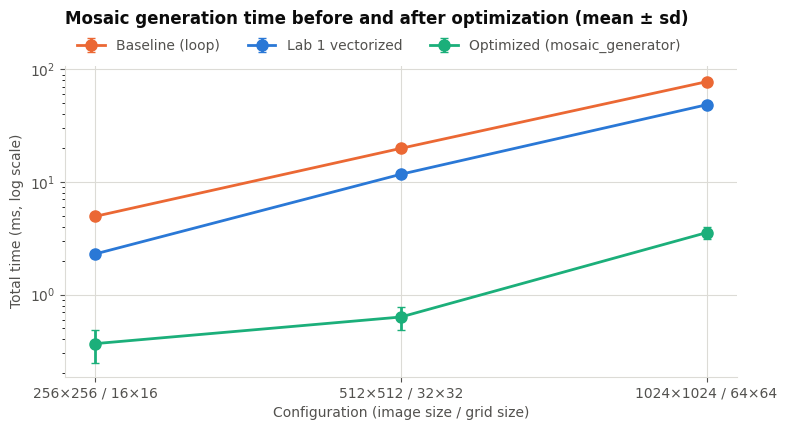

In [24]:
C_V2 = "#1baf7a"   # third color of the same validated palette, after orange (loop) and blue (Lab 1)
VERSIONS = (("loop_ms", "loop_sd", C_LOOP, "Baseline (loop)"),
            ("vec_ms", "vec_sd", C_VEC, "Lab 1 vectorized"),
            ("v2_ms", "v2_sd", C_V2, "Optimized (mosaic_generator)"))

fig, ax = plt.subplots(figsize=(8, 4.4))
for col, sd, color, label in VERSIONS:
    ax.errorbar(x, after[col], yerr=after[sd], color=color, lw=2, marker="o", ms=8,
                capsize=3, label=label)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(CONFIG_LABELS, color=INK)
ax.set_xlabel("Configuration (image size / grid size)", color=MUTED)
ax.set_ylabel("Total time (ms, log scale)", color=MUTED)
style_axes(ax)
ax.set_title("Mosaic generation time before and after optimization (mean ± sd)", loc="left",
             color=INK, fontsize=12, fontweight="bold", pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, labelcolor=MUTED)
plt.tight_layout()
plt.savefig(RESULTS / "optimized_scaling.png", dpi=140)
plt.show()

I also draw two bar charts. In the first one, I compare the execution times of the three versions. In the second one, I show how many times faster my optimized version is, and I mark the 20× target with a dashed line.

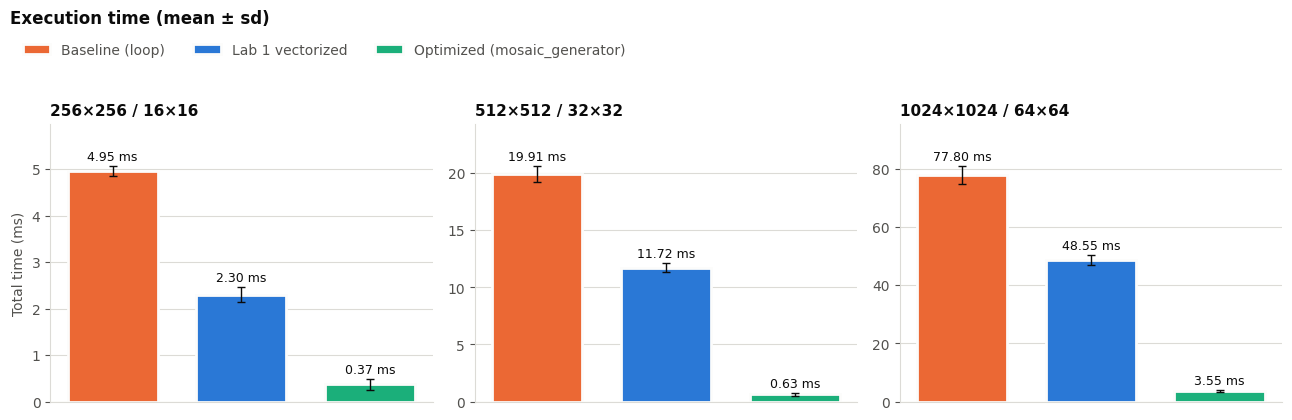

In [25]:
SURFACE = "#fcfcfb"

# One panel per configuration: the times differ by about 15x between the configurations, so
# each panel gets its own linear axis starting at zero instead of one shared log axis.
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (_, r), label in zip(axes, after.iterrows(), CONFIG_LABELS):
    for i, (col, sd, color, name) in enumerate(VERSIONS):
        ax.bar(i, r[col], yerr=r[sd], width=0.7, color=color, edgecolor=SURFACE, linewidth=2,
               capsize=3, error_kw=dict(ecolor=INK, lw=1), label=name)
        ax.annotate(f"{r[col]:.2f} ms", (i, r[col] + r[sd]), textcoords="offset points",
                    xytext=(0, 4), ha="center", color=INK, fontsize=9)
    ax.set_xticks([])
    ax.set_ylim(0, max(r.loop_ms + r.loop_sd, r.vec_ms + r.vec_sd) * 1.18)
    ax.set_title(label, loc="left", color=INK, fontsize=11, fontweight="bold")
    style_axes(ax, grid_axis="y")

axes[0].set_ylabel("Total time (ms)", color=MUTED)
fig.suptitle("Execution time (mean ± sd)", x=0.01, y=0.99, ha="left", color=INK,
             fontsize=12, fontweight="bold")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.94), ncol=3,
           frameon=False, labelcolor=MUTED)
plt.tight_layout(rect=(0, 0, 1, 0.88))
plt.savefig(RESULTS / "execution_time_bars.png", dpi=140)
plt.show()

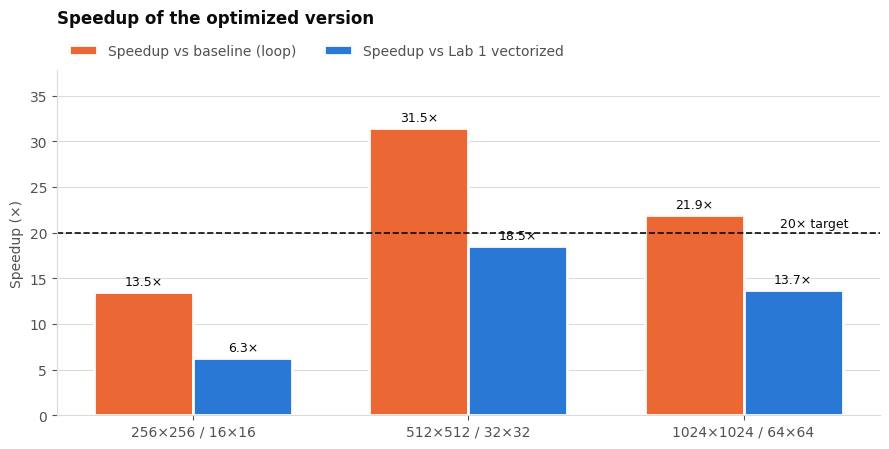

In [26]:
TARGET = 20
width = 0.36

# Each bar is colored like the version the optimized code is compared against.
fig, ax = plt.subplots(figsize=(9, 4.6))
for offset, col, color, name in ((-width / 2, "speedup_vs_loop", C_LOOP, "vs baseline (loop)"),
                                 (width / 2, "speedup_vs_vec", C_VEC, "vs Lab 1 vectorized")):
    bars = ax.bar(x + offset, after[col], width=width, color=color, edgecolor=SURFACE,
                  linewidth=2, label=f"Speedup {name}")
    ax.bar_label(bars, labels=[f"{v:.1f}×" for v in after[col]], padding=3, color=INK,
                 fontsize=9)

ax.axhline(TARGET, color=INK, lw=1.2, ls="--")
ax.annotate(f"{TARGET}× target", (x[-1] + width, TARGET), textcoords="offset points",
            xytext=(4, 4), ha="right", color=INK, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(CONFIG_LABELS, color=INK)
ax.set_ylabel("Speedup (×)", color=MUTED)
ax.set_ylim(0, max(after.speedup_vs_loop.max(), after.speedup_vs_vec.max(), TARGET) * 1.2)
style_axes(ax, grid_axis="y")
ax.set_title("Speedup of the optimized version", loc="left", color=INK, fontsize=12,
             fontweight="bold", pad=34)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, labelcolor=MUTED)
plt.tight_layout()
plt.savefig(RESULTS / "speedup_bars.png", dpi=140)
plt.show()

#### What the Results Show

**The 20× target is met.** On 512×512 with a 32×32 grid, the optimized version takes **0.63 ms** instead of **19.9 ms**, so it is **31.5× faster** than the baseline. It is also 18.5× faster than my Lab 1 vectorized code. For the other two configurations, I get 13.5× (256×256 / 16×16) and 21.9× (1024×1024 / 64×64).

From the charts, I can see that the speedup is not the same for all three configurations. On the smallest image, the optimized version only needs about 0.37 ms, and part of that is a fixed cost for calling the functions, which does not get smaller with the image. On the largest image, most of the 3.6 ms is spent on moving a lot of image data in memory. The middle configuration is in between, so it gets the biggest speedup.

### 3. Correctness Check

A faster version is only useful if it still makes the same mosaic. So for each of the three configurations, I compare the optimized mosaic with the baseline mosaic, using these metrics:

* **Same tile.** The share of cells where both versions pick the same tile.
* **MSE.** The mean squared error between the two mosaics, over all pixels and color channels.
* **Max difference.** The largest difference of a single pixel value, out of 255.
* **Pixels that differ.** The share of pixel values that are not exactly the same.

In [27]:
from mosaic_generator.metrics import mse

rows = []
for (size, grid), label in zip(CONFIGS, CONFIG_LABELS):
    img, kw = test_images[size], settings(size, grid)
    ref = build_mosaic_loop(img, **kw)
    new = mosaic_generator.build_mosaic(img, **kw)
    diff = np.abs(new.mosaic_full.astype(int) - ref.mosaic_full.astype(int))
    rows.append({
        "Configuration": label,
        "Same tile": f"{(new.indices == ref.indices).mean():.1%}",
        "MSE": f"{mse(ref.mosaic_full, new.mosaic_full):.3f}",
        "Max difference": int(diff.max()),
        "Pixels that differ": f"{np.count_nonzero(diff) / diff.size:.1%}",
    })

pd.DataFrame(rows)

,Configuration,Same tile,MSE,Max difference,Pixels that differ
0,256×256 / 16×16,100.0%,0.268,1,26.8%
1,512×512 / 32×32,100.0%,0.269,1,26.9%
2,1024×1024 / 64×64,100.0%,0.246,1,24.6%


To see the difference with my own eyes, I also show both mosaics for 512×512 / 32×32 side by side, together with a map of where they differ.

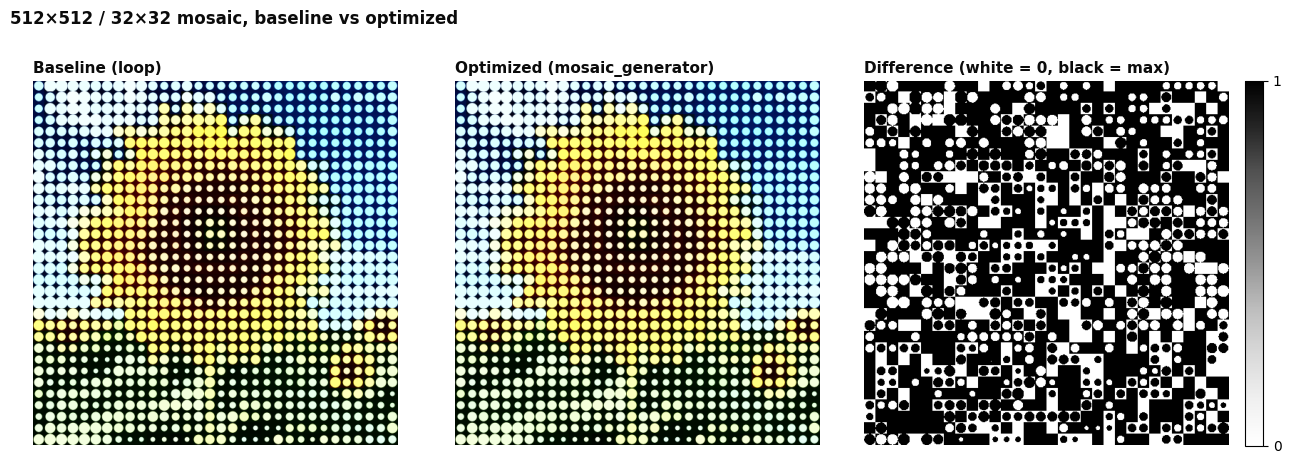

In [28]:
img, kw = test_images[512], settings(512, 32)
ref = build_mosaic_loop(img, **kw).mosaic_full
new = mosaic_generator.build_mosaic(img, **kw).mosaic_full
diff = np.abs(new.astype(int) - ref.astype(int)).max(axis=2)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, im, title in zip(axes[:2], (ref, new), ("Baseline (loop)", "Optimized (mosaic_generator)")):
    ax.imshow(im)
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.axis("off")
shown = axes[2].imshow(diff, cmap="Greys", vmin=0, vmax=max(1, diff.max()))
axes[2].set_title("Difference (white = 0, black = max)", loc="left", color=INK, fontsize=11,
                  fontweight="bold")
axes[2].axis("off")
fig.colorbar(shown, ax=axes[2], fraction=0.046, pad=0.04, ticks=range(diff.max() + 1))
fig.suptitle("512×512 / 32×32 mosaic, baseline vs optimized", x=0.01, y=0.98, ha="left",
             color=INK, fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93))   # leave room so the title does not touch the panels
plt.show()

#### What the Check Shows

From the result, I find that **both versions pick the same tile in 100% of the cells**, in all three configurations. So the optimized matching makes exactly the same choices as the baseline loop.

I can also see that the pixel values are never more than **1 level out of 255** apart. About 25% to 27% of the values differ by this 1 level, so the MSE is only about 0.25 to 0.27. This small difference comes from optimization 6, where I round the colors to uint8.

In the picture, the two mosaics look the same. The difference map looks busy, but black only means a difference of 1 level, which is too small to see. So the optimized mosaic is essentially identical to the baseline.